# Generative Artificial Intelligence — Lab 2: GANs and Conditional GANs
**University of Boumerdes (UMBB) — Master 2, Field I2A — Faculty of Sciences, Department of Computer Science — Academic year 2026/2027**

with PyTorch, on MNIST, then on Pokémon and flower images

## Objectives
At the end of this lab, you will be able to:
- build a generator and a discriminator in PyTorch and train them one against the other;
- write the training loop of a GAN in two phases, and explain the role of `.detach()` and of the labels 0 and 1;
- replace the linear layers with convolutions (DCGAN) and check the size of every layer;
- build a conditional GAN (cGAN): give the class to both networks and choose the class of the generated image;
- download a dataset from Kaggle (`kagglehub` or *Add Input*), prepare colour images (transparency, size, range) and do the same work on 64 × 64 colour images: a DCGAN on Pokémon images, a conditional GAN on flower photos;
- read the loss curves of a GAN, and check if a generator copies its training images.

This document explains every block of code of the lab. Read the explanation, run the code, look at the output, then answer the questions. Some lines of code are missing: they are marked `# TODO` with a hint. Complete them before you run the block. The Python packages needed for the lab are listed in the file `requirements.txt`.

**Plan.** The lab is done on MNIST, step by step. After each part, an exercise asks you to do the same work on a new colour dataset from Kaggle.

| Part | Model | Dataset | Images |
|---|---|---|---|
| Section 1 | GAN (linear), then DCGAN | MNIST | 1 × 28 × 28, gray |
| Exercise A | DCGAN | Pokémon (819 images, no labels) | 3 × 64 × 64, colour |
| Section 2 | conditional GAN | MNIST (10 digits) | 1 × 28 × 28, gray |
| Exercise B | conditional GAN | Flowers (5 classes) | 3 × 64 × 64, colour |

# Section 0 — Prepare the environment

## 0.1 On your PC (CPU or GPU)
We use the environment `genai` of Lab 1. If you do not have it, follow Section 0 of Lab 1 (clone base, install PyTorch for the CPU or for your GPU). Then open Anaconda Prompt (or a terminal) in the folder of the lab:

```
conda activate genai
pip install -r requirements.txt
jupyter notebook
```

The only new package is `kagglehub`: it downloads datasets from Kaggle (Exercises A and B). In Jupyter, choose the kernel "Python (genai)".

## 0.2 On Google Colab or Kaggle
PyTorch is already installed. Choose a GPU: on Colab, *Runtime → Change runtime type → T4 GPU*; on Kaggle, in the right panel, *Accelerator → GPU* and *Internet → On*. `kagglehub` is installed on both. On Colab, if the import fails, run `!pip install kagglehub` in a cell.

## 0.3 Check

In [5]:
import sys, platform
import torch, torchvision, numpy, matplotlib

print("Python :", sys.version.split()[0], "on", platform.system())
print("PyTorch :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

try:
    import kagglehub
    print("kagglehub is installed, version", kagglehub.__version__)
except ImportError:
    print("kagglehub is missing: run pip install kagglehub")

Python : 3.12.3 on Linux
PyTorch : 2.15.0+cu132
torchvision : 0.29.2+cu132
CUDA available: False
kagglehub is installed, version 1.0.3


/home/asura/projects/asura-mlkit/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The line `CUDA available` must be `True` on Colab and Kaggle. On a PC without an NVIDIA GPU it is `False`: the lab still works, but slower.

> **Training time.** A GAN must be trained much longer than the autoencoders of Lab 1. The number of epochs in the code is chosen so that every section runs in a reasonable time on a CPU, so the images are not perfect. Each `n_epochs` line has a comment with a better value for a GPU. With a GPU, use these values: the difference is very visible.

# Section 1 — A GAN on MNIST

**Goal.** Two networks play a game:
- the **generator** $G$ takes a random vector $z$ (the noise, 100 numbers from $\mathcal{N}(0, 1)$) and returns an image $G(z)$;
- the **discriminator** $D$ takes an image and returns a score: high if it thinks the image is real, low if it thinks the image is fake.

$D$ learns to separate real and fake images. $G$ learns to fool $D$. At the end, we throw away $D$ and we keep $G$: it turns any random $z$ into a new digit.

## 1.1 Imports and helper functions

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.utils import make_grid

%matplotlib inline

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)


def show_images(images, nrow=8, title=None, size=6):
    # images: tensor (N, C, H, W) with values in [-1, 1]
    grid = make_grid(images.detach().cpu(), nrow=nrow, padding=2,
                     normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(size, size))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_losses(history, title):
    plt.figure(figsize=(7, 3.5))
    plt.plot(history["d"], label="discriminator", alpha=0.8)
    plt.plot(history["g"], label="generator", alpha=0.8)
    plt.xlabel("iteration")
    plt.ylabel("loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

PyTorch version: 2.15.0+cu132
Device: cpu


- `show_images` draws a batch of images as a grid with `make_grid`. It works for gray and colour images. `normalize=True, value_range=(-1, 1)` maps the values from $[-1, 1]$ back to $[0, 1]$ for the display.
- `plot_losses` draws the two losses (one value per batch). We use both functions in the whole lab.

## 1.2 The data

100%|██████████| 9.91M/9.91M [00:11<00:00, 878kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 140kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 355kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.01MB/s]


One batch: (128, 1, 28, 28)
Values between 0.0 and 1.0


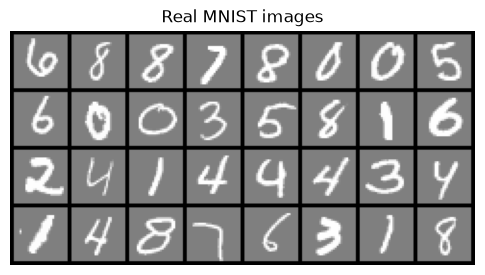

In [2]:
# ToTensor gives values in [0, 1]; Normalize(0.5, 0.5) maps them to [-1, 1],
# the same range as the Tanh at the output of the generator.
transform = transforms.Compose([
    transforms.ToTensor(),
    # TODO: map the pixels from [0, 1] to [-1, 1]
])

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True,
                                           drop_last=True)

images, labels = next(iter(train_loader))
print("One batch:", tuple(images.shape))
print("Values between", images.min().item(), "and", images.max().item())
show_images(images[:32], title="Real MNIST images")

- `ToTensor()` gives pixels in $[0, 1]$. `Normalize(mean, std)` computes $(x - \text{mean})/\text{std}$ for each channel. Choose `mean` and `std` so that the pixels are in $[-1, 1]$ (MNIST has one channel: write them as tuples of one value).
- **Why?** The last layer of the generator is a `Tanh`, whose outputs are in $[-1, 1]$. Real and fake images must be in the same range, otherwise the discriminator wins at once just by looking at the range of the values.
- `drop_last=True`: all batches have exactly 128 images (the last, smaller batch is dropped). This keeps the BatchNorm layers of the next models stable.

Expected output:
```
One batch: (128, 1, 28, 28) | values between -1.0 and 1.0
```

## 1.3 A linear GAN

In [7]:
z_dim = 100   # size of the noise vector

class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 28 * 28), nn.Tanh())     # pixels in [-1, 1]

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)       # vector -> image


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                            # image -> vector
            nn.Linear(28 * 28, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1))                       # one score (a logit, no sigmoid)

    def forward(self, x):
        return self.net(x)


G = Generator(z_dim).to(device)
D = Discriminator().to(device)
print("Generator parameters    :", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

Generator parameters    : 559632
Discriminator parameters: 533505


| | Generator | Discriminator |
|---|---|---|
| input | noise $z$: 100 | image: 1 × 28 × 28, flattened to 784 |
| hidden layers | 256, 512 (LeakyReLU) | 512, 256 (LeakyReLU) |
| output | 784 values, Tanh, reshaped to 1 × 28 × 28 | 1 value (a logit) |

- The two networks are mirrors: $G$ goes from a small vector to an image, $D$ from an image to one number.
- `LeakyReLU(0.2)`: like ReLU, but negative inputs give a small negative output ($0.2x$) instead of 0. The gradient never becomes exactly zero: this helps the generator, which learns only through the gradients that come back from $D$.
- The discriminator has **no sigmoid**. Its output is a *logit* (any real number). The sigmoid is inside the loss (next block).

Expected output:
```
Generator parameters : 559632
Discriminator parameters: 533505
```

## 1.4 The loss and the training loop
The discriminator is a binary classifier: real → 1, fake → 0. With the binary cross-entropy, its loss is

$$L_D = -\big[\log D(x) + \log\big(1 - D(G(z))\big)\big]$$

and the generator wants $D$ to answer "real" on its images:

$$L_G = -\log D(G(z)).$$

(This is the "non-saturating" loss of the lecture. The original loss $\log(1 - D(G(z)))$ gives almost no gradient at the beginning, when $D$ easily rejects the fakes.)

In [8]:
criterion = nn.BCEWithLogitsLoss()   # sigmoid + binary cross-entropy, in one stable function


def train_gan(G, D, loader, n_epochs, z_dim, lr=2e-4):
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    fixed_z = torch.randn(64, z_dim, device=device)   # the same noise at every epoch
    history = {"d": [], "g": [], "samples": []}

    for epoch in range(1, n_epochs + 1):
        G.train(); D.train()
        for real, _ in loader:                         # the labels are not used
            real = real.to(device)
            B = real.size(0)
            ones = torch.ones(B, 1, device=device)
            zeros = torch.zeros(B, 1, device=device)

            # ---------- Phase 1: train the discriminator ----------
            z = torch.randn(B, z_dim, device=device)
            fake = ...      # TODO: generate fake images WITHOUT gradient for G
            loss_d = ...    # TODO: real -> 1, fake -> 0
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

            # ---------- Phase 2: train the generator ----------
            z = torch.randn(B, z_dim, device=device)
            fake = G(z)
            loss_g = ...    # TODO: the generator wants D to answer "real"
            opt_g.zero_grad()
            loss_g.backward()
            opt_g.step()

            history["d"].append(loss_d.item())
            history["g"].append(loss_g.item())

        G.eval()
        with torch.no_grad():
            history["samples"].append(G(fixed_z).cpu())
        print(f"Epoch {epoch:2d}/{n_epochs} | loss D: {loss_d.item():.3f} "
              f"| loss G: {loss_g.item():.3f}")
    return history

- `BCEWithLogitsLoss` = sigmoid + binary cross-entropy in one function. It is more stable than `Sigmoid` followed by `BCELoss`.
- **Two networks, so two optimizers.** `opt_d` changes only the weights of $D$, `opt_g` only the weights of $G$. The values `lr=2e-4` and `betas=(0.5, 0.999)` come from the DCGAN paper; they work well for most GANs.
- **Phase 1 (discriminator).** $D$ sees a batch of real images (target 1) and a batch of fake images (target 0). The fake images must be used as simple inputs: no gradient must go back into $G$. Find the tensor method that cuts a tensor from the computation graph.
- **Phase 2 (generator).** New fake images, this time *without* detach, and the target is **1**: the generator is rewarded when $D$ is fooled. The gradient goes through $D$ into $G$, but only `opt_g.step()` is called, so only $G$ changes.
- `fixed_z`: 64 noise vectors chosen once. After every epoch we draw $G(\texttt{fixed\_z})$: we see the *same* 64 images improve epoch after epoch.

## 1.5 Training

In [9]:
n_epochs = 5        # increase it if you have a GPU (30 or more)
history = train_gan(G, D, train_loader, n_epochs, z_dim)

AttributeError: 'ellipsis' object has no attribute 'backward'

Expected output (the values change from one run to another):
```
Epoch  1/5 | loss D: 0.840 | loss G: 1.269
Epoch  2/5 | loss D: 0.788 | loss G: 3.581
Epoch  3/5 | loss D: 1.156 | loss G: 0.827
Epoch  4/5 | loss D: 1.908 | loss G: 1.335
Epoch  5/5 | loss D: 0.586 | loss G: 1.707
```

## 1.6 Results

In [ ]:
plot_losses(history, "Linear GAN on MNIST")

# the same 64 noise vectors, after the first and after the last epoch
show_images(history["samples"][0][:32], title="After epoch 1", size=5)
show_images(history["samples"][-1][:32], title=f"After epoch {n_epochs}", size=5)

The losses do **not** go down to zero like the loss of a classifier. Each network gets better, but so does its opponent: the two losses oscillate around a balance. A loss of $D$ that falls to 0 (and a loss of $G$ that keeps growing) means that $D$ has won and $G$ no longer learns.

The same noise vectors after the first epoch (left) and after the last epoch (right). After one epoch the generator only draws a grey blob in the middle of the image; after five epochs the blobs have the shape of digits, but they are still noisy. A linear generator needs many more epochs to give clean digits.

## 1.7 A convolutional GAN (DCGAN)
Images have a spatial structure. As in Lab 1 (convolutional autoencoder), we replace the linear layers by convolutions: `Conv2d` with `stride=2` in $D$ (the image becomes smaller), `ConvTranspose2d` with `stride=2` in $G$ (the image becomes larger).

In [ ]:
class DCGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z_dim, 128 * 7 * 7),
                                nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),   # 7 -> 14
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1),     # 14 -> 28
            nn.Tanh())

    def forward(self, z):
        x = self.fc(z).view(-1, 128, 7, 7)       # vector -> 7 x 7 feature map
        return self.net(x)


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, stride=2, padding=1),              # 28 -> 14
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),            # 14 -> 7
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1))

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
G_dc = DCGenerator(z_dim).to(device)
D_dc = DCDiscriminator().to(device)

# check the shapes before training
z = torch.randn(4, z_dim, device=device)
print("generator output    :", tuple(G_dc(z).shape))
print("discriminator output:", tuple(D_dc(G_dc(z)).shape))

| Generator | | Discriminator | |
|---|---|---|---|
| $z$ | 100 | image | 1 × 28 × 28 |
| Linear, reshape | 128 × 7 × 7 | Conv2d(k=4, s=2, p=1) | 64 × 14 × 14 |
| ConvTranspose2d(k=4, s=2, p=1) | 64 × 14 × 14 | Conv2d(k=4, s=2, p=1) | 128 × 7 × 7 |
| ConvTranspose2d(k=4, s=2, p=1) | 1 × 28 × 28 | Flatten, Linear | 1 |

With $k = 4$, $s = 2$, $p = 1$, a transposed convolution doubles the size, $(n-1)\times 2 - 2 + 4 = 2n$, and a convolution halves it, $\lfloor (n + 2 - 4)/2 \rfloor + 1 = n/2$. The DCGAN rules are used: BatchNorm in both networks (not on the output of $G$ nor on the input of $D$), ReLU in $G$, LeakyReLU in $D$, Tanh at the end of $G$.

Expected output:
```
generator output    : (4, 1, 28, 28)
discriminator output: (4, 1)
```

## 1.8 Training the DCGAN

In [ ]:
n_epochs_dc = 3     # increase it if you have a GPU (20 or more)
history_dc = train_gan(G_dc, D_dc, train_loader, n_epochs_dc, z_dim)
plot_losses(history_dc, "DCGAN on MNIST")
show_images(history_dc["samples"][-1], title=f"DCGAN, after epoch {n_epochs_dc}", size=6)

The function `train_gan` is reused without any change: it does not depend on the architecture.

After only 3 epochs the background is clean and the strokes are continuous: the convolutions learn local patterns (edges, strokes) much faster than the linear layers. Some digits are still badly formed; with 20 epochs or more they become very good.

**Question 1.1.** Why do we call `.detach()` on the fake images in Phase 1, and not in Phase 2?

**Question 1.2.** In Phase 2, the fake images get the target 1. Explain why. What would happen with the target 0?

**Question 1.3.** Look at the loss curves. Do they go down like the loss of a classifier? Why?

**Question 1.4.** The generator never sees a real image. How does it learn to draw digits?

**Question 1.5.** Compare the images of the linear GAN and of the DCGAN. Count the parameters of each generator.

**Question 1.6.** *(Exercise)* Remove `Normalize` from the transform (pixels in $[0, 1]$) and train the linear GAN again for 2 epochs. What happens? Why?

*Your answers:*

In [ ]:
# Question 1.5: parameters of each generator
print("Linear generator:", sum(p.numel() for p in G.parameters()))
print("DCGAN generator :", sum(p.numel() for p in G_dc.parameters()))

# Exercise A — The same work on Pokémon images

**Goal.** Do the work of Section 1 on a real colour dataset: train a DCGAN on images of Pokémon, at 64 × 64 pixels.

**Dataset.** *Pokémon Images Dataset*, <https://www.kaggle.com/datasets/kvpratama/pokemon-images-dataset>. It contains 819 images, each in two versions: PNG with a transparent background, and JPG on a white background (about 40 MB).

> **GAN or conditional GAN?** A conditional GAN needs a label for every training image. This dataset contains only images: no class, no type, no name (the files are just numbered). So we train a normal (unconditional) DCGAN here. The conditional GAN on colour images is Exercise B.

## A.1 Get the dataset
**On a PC or on Colab.** Run Section 1.1 and the function `train_gan` of 1.4 first, then:

In [ ]:
import kagglehub

# PC / Colab: downloads the dataset once (about 40 MB) and returns the local folder.
# Kaggle: add the dataset with "Add Input" (right panel); the same line returns its folder.
path = kagglehub.dataset_download("kvpratama/pokemon-images-dataset")
print("Path to dataset files:", path)

`kagglehub.dataset_download` downloads the dataset the first time, then reuses the local copy (in a cache folder of your home directory). It returns the path of that folder. The dataset is public: no Kaggle account is needed. If a message asks you to log in, create a token on <https://www.kaggle.com/settings> (*API → Create New Token*) and follow the message.

**On Kaggle.** Open your notebook, then in the right panel: *Add Input → Datasets →* search "pokemon images dataset" (author kvpratama) *→ Add*. The files appear under `/kaggle/input/`, without any download. The code above works too: it returns the folder of the dataset.

**Without kagglehub.** Click *Download* on the page of the dataset, unzip the file in the folder of your notebook, and write `path = "pokemon-images-dataset"` (the name of the unzipped folder).

## A.2 Work to do
1. **Load the images.** Find all the image files with `glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)` (the folder is not the same on a PC, on Colab and on Kaggle). If you use the PNG files, put each image on a white background first (`Image.alpha_composite`). Resize the images to 64 × 64 (`Image.BICUBIC`).
2. **Build a `Dataset`** that keeps the 819 images in memory and returns pairs `(image, 0)`: `train_gan` expects a label, which it ignores. Use `RandomHorizontalFlip()`, `ToTensor()` and a `Normalize` with 3 values (one per channel). Use a `DataLoader` with `batch_size=32, shuffle=True, drop_last=True`. Show 32 real images with `show_images`.
3. **Build the DCGAN** of the table below, with `ngf = ndf = 32` on a CPU (64 on a GPU), and initialize all weights with $\mathcal{N}(0, 0.02)$ (DCGAN paper). Check the shapes: the generator must return `(B, 3, 64, 64)` and the discriminator `(B, 1)`.
4. **Train** with the function `train_gan` of Section 1, without any change: 150 epochs on a CPU, 500 or more on a GPU. Draw the losses.
5. **Show** the generated images after 10 epochs, 50 epochs and at the end (`history["samples"]`).
6. **Check if the generator copies its training images:** for 6 generated images, find the closest real image (smallest pixel distance, `torch.cdist`) and show the two rows.

| Generator | | Discriminator | |
|---|---|---|---|
| $z$ (seen as an image) | 100 × 1 × 1 | image | 3 × 64 × 64 |
| ConvT(k=4, s=1, p=0) | 8·ngf × 4 × 4 | Conv(k=4, s=2, p=1) | ndf × 32 × 32 |
| ConvT(k=4, s=2, p=1) | 4·ngf × 8 × 8 | Conv(k=4, s=2, p=1) | 2·ndf × 16 × 16 |
| ConvT(k=4, s=2, p=1) | 2·ngf × 16 × 16 | Conv(k=4, s=2, p=1) | 4·ndf × 8 × 8 |
| ConvT(k=4, s=2, p=1) | ngf × 32 × 32 | Conv(k=4, s=2, p=1) | 8·ndf × 4 × 4 |
| ConvT(k=4, s=2, p=1), Tanh | 3 × 64 × 64 | Conv(k=4, s=1, p=0) | 1 × 1 × 1 |

Each transposed convolution with $k=4$, $s=2$, $p=1$ doubles the size; the first one ($k=4$, $s=1$, $p=0$) turns $z$, seen as a 1 × 1 image with 100 channels, into a 4 × 4 map: $(1-1)\times 1 - 0 + 4 = 4$. The discriminator does the opposite. Use `bias=False` before a BatchNorm, BatchNorm in both networks (not on the output of $G$ nor on the input of $D$), ReLU in $G$, LeakyReLU(0.2) in $D$, Tanh at the end of $G$.

In [ ]:
# A.2 — 1. Load the images
import glob
from PIL import Image

In [ ]:
# A.2 — 2. Dataset, transforms, DataLoader (batch_size=32), show 32 real images

In [ ]:
# A.2 — 3. DCGAN (ngf = ndf = 32 on CPU, 64 on GPU), N(0, 0.02) initialization, shape check

In [ ]:
# A.2 — 4. Training with train_gan (150 epochs on CPU, 500+ on GPU), plot the losses

In [ ]:
# A.2 — 5. Generated images after 10 epochs, 50 epochs and at the end (history["samples"])

In [ ]:
# A.2 — 6. Closest real image (torch.cdist) for 6 generated images

## Questions (Exercise A)

**Question A.1.** Why can we not train a conditional GAN on this dataset? What would we need?

**Question A.2.** What happens to the transparent background if we use `Image.open(f).convert("RGB")` directly on the PNG files? Try it.

**Question A.3.** Compute the number of updates of $G$ in the MNIST GAN (Section 1.5) and in this exercise. Explain why we need many more epochs here.

**Question A.4.** Look at the images after 10, 50 and `n_epochs_p` epochs. What does the generator learn first?

**Question A.5.** Look at the test "closest real image". Does the generator copy the training images?

*Your answers:*

# Section 2 — A conditional GAN (cGAN) on MNIST

**Goal.** The GAN of Section 1 draws a *random* digit: we cannot choose which one. A conditional GAN receives an extra input $y$, the class (here, the digit 0 to 9):

$$G(z, y) \to \text{an image of class } y, \qquad D(x, y) \to \text{"is } x \text{ a real image of class } y\text{?"}$$

The discriminator now rejects two kinds of fakes: images that do not look real, and real-looking images that do not match their label. So the generator must respect the class.

## 2.1 Imports, helpers and data
The block of 1.1 (imports, `show_images`, `plot_losses`) is the same. The data are the same as in 1.2, but now we keep the labels:

In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True,
                                           drop_last=True)
n_classes = 10
z_dim = 100

## 2.2 The two networks

In [ ]:
class CondGenerator(nn.Module):
    def __init__(self, z_dim=100, n_classes=10, emb_dim=10):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, emb_dim)      # class number -> small vector
        self.fc = nn.Sequential(nn.Linear(z_dim + emb_dim, 128 * 7 * 7),
                                nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),   # 7 -> 14
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1),     # 14 -> 28
            nn.Tanh())

    def forward(self, z, y):
        h = ...        # TODO: join the noise and the label vector
        x = self.fc(h).view(-1, 128, 7, 7)
        return self.net(x)


class CondDiscriminator(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        # the label becomes a full 28 x 28 map, added to the image as a second channel
        self.label_emb = nn.Embedding(n_classes, 28 * 28)
        self.net = nn.Sequential(
            nn.Conv2d(2, 64, 4, stride=2, padding=1),          # 2 channels: image + label
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1))

    def forward(self, x, y):
        label_map = self.label_emb(y).view(-1, 1, 28, 28)
        h = ...        # TODO: join image and label map (channel axis)
        return self.net(h)


torch.manual_seed(0)
G_c = CondGenerator(z_dim, n_classes).to(device)
D_c = CondDiscriminator(n_classes).to(device)

z = torch.randn(4, z_dim, device=device)
y = torch.tensor([0, 1, 2, 3], device=device)
print("generator output    :", tuple(G_c(z, y).shape))
print("discriminator output:", tuple(D_c(G_c(z, y), y).shape))

- `nn.Embedding(10, 10)` is a table of 10 learnable vectors: the class number `y` selects its row. It is a learned version of the one-hot vector.
- **Generator:** the noise (100) and the label vector (10) are joined with `torch.cat(..., dim=1)` into one vector of 110 numbers. The rest is the DCGAN generator of 1.7.
- **Discriminator:** an image has a shape 1×28×28, a label vector does not. So the label is turned into a full 28 × 28 map (`Embedding(10, 784)`, then `view`) and added as a second channel: the first `Conv2d` has 2 input channels. `dim=1` is the channel axis of a batch (B, C, H, W).

Expected output:
```
generator output    : (4, 1, 28, 28)
discriminator output: (4, 1)
```

## 2.3 Training

In [ ]:
criterion = nn.BCEWithLogitsLoss()


def train_cgan(G, D, loader, n_epochs, z_dim, n_classes, lr=2e-4):
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    history = {"d": [], "g": []}

    for epoch in range(1, n_epochs + 1):
        G.train(); D.train()
        for real, labels in loader:                    # now the labels ARE used
            real, labels = real.to(device), labels.to(device)
            B = real.size(0)
            ones = torch.ones(B, 1, device=device)
            zeros = torch.zeros(B, 1, device=device)

            # ---------- Phase 1: discriminator ----------
            z = torch.randn(B, z_dim, device=device)
            # random classes for the fake images
            fake_labels = torch.randint(0, n_classes, (B,), device=device)
            fake = G(z, fake_labels).detach()
            loss_d = ...    # TODO: give D the labels too
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

            # ---------- Phase 2: generator ----------
            z = torch.randn(B, z_dim, device=device)
            fake_labels = torch.randint(0, n_classes, (B,), device=device)
            loss_g = ...    # TODO: fake image AND its class must look real
            opt_g.zero_grad()
            loss_g.backward()
            opt_g.step()

            history["d"].append(loss_d.item())
            history["g"].append(loss_g.item())

        print(f"Epoch {epoch:2d}/{n_epochs} | loss D: {loss_d.item():.3f} "
              f"| loss G: {loss_g.item():.3f}")
    return history

- The loop is the loop of 1.4, with the labels added to every call of $G$ and $D$.
- Real images come with their **true labels**. Fake images get **random labels** (`torch.randint`): the generator must learn every class.
- In Phase 2, the discriminator receives the fake image and the label that was asked. If the image is a nice "3" but the label was "8", $D$ answers "fake", and $G$ is pushed to draw an "8".

In [ ]:
n_epochs = 3        # increase it if you have a GPU (20 or more)
history_c = train_cgan(G_c, D_c, train_loader, n_epochs, z_dim, n_classes)
plot_losses(history_c, "Conditional GAN on MNIST")

Expected output:
```
Epoch 1/3 | loss D: 0.844 | loss G: 1.552
Epoch 2/3 | loss D: 0.835 | loss G: 1.022
Epoch 3/3 | loss D: 0.990 | loss G: 0.618
```

## 2.4 One row per class

In [ ]:
def class_grid(G, n_classes, z_dim, n_per_class=10):
    # one row per class: row k contains n_per_class images of class k
    G.eval()
    with torch.no_grad():
        y = torch.arange(n_classes, device=device).repeat_interleave(n_per_class)
        z = torch.randn(n_classes * n_per_class, z_dim, device=device)
        return G(z, y)


torch.manual_seed(1)
show_images(class_grid(G_c, n_classes, z_dim), nrow=10, title="Row k = class k", size=7)

`repeat_interleave(10)` gives the labels 0,0,...,0,1,1,...,9: with `nrow=10`, row $k$ of the grid contains ten images generated with the label $k$, each with a different noise $z$.

## 2.5 Choose the digit

In [ ]:
def generate_digit(G, digit, n=10):
    G.eval()
    with torch.no_grad():
        z = torch.randn(n, z_dim, device=device)
        y = ...        # TODO: n times the chosen class
        return G(z, y)


show_images(generate_digit(G_c, 7), nrow=10, title="Ten generated 7s", size=7)

`torch.full((n,), digit)` is a tensor of $n$ times the same label. This is what a cGAN gives: we ask for a "7", we get ten different "7"s.

## 2.6 Same noise, different classes

In [ ]:
# the SAME noise z for every column, the class changes from 0 to 9:
# z controls the style (thickness, slant), y controls the digit
torch.manual_seed(2)
z = torch.randn(1, z_dim, device=device).repeat(10, 1)
y = torch.arange(10, device=device)
with torch.no_grad():
    G_c.eval()
    show_images(G_c(z, y), nrow=10, title="Same z, classes 0 to 9", size=7)

All ten images use the same $z$. The digits change, but they share the same *style* (thickness, slant, size). The label $y$ decides **what** is drawn; the noise $z$ decides **how** it is drawn.

**Question 2.1.** Why are the fake labels random, and not the labels of the real batch?

**Question 2.2.** What does the discriminator check in a cGAN that it does not check in a GAN?

**Question 2.3.** In 2.6, which properties of the digit are controlled by $z$? By $y$?

**Question 2.4.** *(Exercise)* Replace the `Embedding` of the generator by a one-hot vector (`F.one_hot(y, 10).float()`). Which line(s) must change? Does it still work?

**Question 2.5.** *(Exercise)* Train a small CNN classifier on MNIST and use it to check the generator: for 1 000 generated digits (100 per class), how often does the classifier find the class that we asked for?

*Your answers:*

In [ ]:
# Question 2.4 / 2.5 — your code here

# Exercise B — A conditional GAN on flower photos

**Goal.** Do the work of Section 2 on colour photos: train a conditional GAN that draws the flower we ask for, at 64 × 64 pixels.

**Dataset.** *Flowers Recognition*, <https://www.kaggle.com/datasets/alxmamaev/flowers-recognition>. About 4 200 colour photos (about 230 MB) in 5 classes: daisy, dandelion, rose, sunflower, tulip. There is one folder per class: **the label of an image is the name of its folder**. The photos have different sizes.

## B.1 Get the dataset
**On a PC or on Colab.** Run Section 1.1, and the functions `train_cgan` (2.3) and `class_grid` (2.4) first, then:

In [ ]:
import kagglehub

# PC / Colab: downloads the dataset once (about 230 MB) and returns the local folder.
# Kaggle: add the dataset with "Add Input" (right panel); the same line returns its folder.
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
print("Path to dataset files:", path)

**On Kaggle.** In the right panel: *Add Input → Datasets →* search "flowers recognition" (author alxmamaev) *→ Add*. The files appear under `/kaggle/input/`; the code above returns their folder.

**Without kagglehub.** Click *Download* on the page of the dataset, unzip the file in the folder of your notebook, and write `path = "flowers-recognition"`.

## B.2 Work to do
1. **Find the images and their labels.** Use the list `classes = ["daisy", "dandelion", "rose", "sunflower", "tulip"]`; the label of an image is the position of its folder name in this list. Search the files with `glob` (`recursive=True`) and keep only the image files (`.jpg`, `.png`). Some versions of the archive contain every image twice (`flowers/` and `flowers/flowers/`): keep each file name only once. Print the number of images of each class.
2. **Prepare the images.** Cut the largest centred square of each photo (`img.crop`), resize it to 64 × 64, and keep all the images in memory. The `Dataset` returns pairs `(image, label)`. Use `RandomHorizontalFlip()`, `ToTensor()`, `Normalize` with 3 values, and batches of 64.
3. **Build the conditional networks** by combining Section 2 and Exercise A:
   - *generator:* the noise (100) and an `Embedding(5, 50)` of the label are joined with `torch.cat`; the vector of 150 values is seen as a 150 × 1 × 1 image and goes through the five transposed convolutions of the Pokémon generator (1 → 4 → 8 → 16 → 32 → 64);
   - *discriminator:* the label becomes a 64 × 64 map (`Embedding(5, 64 * 64)`), joined to the RGB image as a fourth channel; then the five convolutions of the Pokémon discriminator, with 4 input channels.

   Use `ngf = ndf = 32` on a CPU (64 on a GPU) and the initialization $\mathcal{N}(0, 0.02)$. Check the output shapes.
4. **Train** with the function `train_cgan` of Section 2, without any change: 30 epochs on a CPU, 100 or more on a GPU. Draw the losses.
5. **Show one row per class** with `class_grid` (8 images per class), then write a function `generate_flower(G, name, n=8)` that generates `n` images of the class `name` (for example `"sunflower"`).

In [ ]:
# B.2 — 1. Find the images and their labels
import glob
from PIL import Image

classes = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

In [ ]:
# B.2 — 2. Prepare the images (centred square crop, resize to 64 x 64), Dataset, DataLoader (batch 64)

In [ ]:
# B.2 — 3. Conditional generator and discriminator (ngf = ndf = 32 on CPU, 64 on GPU), N(0, 0.02) init, shape check

In [ ]:
# B.2 — 4. Training with train_cgan (30 epochs on CPU, 100+ on GPU), plot the losses

In [ ]:
# B.2 — 5. One row per class with class_grid (8 per class), and generate_flower(G, name, n=8)

## Questions (Exercise B)

**Question B.1.** Why does the discriminator have 3 + 1 input channels?

**Question B.2.** Which rows of the grid are the easiest to recognize? Why?

**Question B.3.** Compare the difficulty of MNIST and of this dataset for a GAN.

**Question B.4.** *(Exercise)* Show the same noise $z$ with the five classes (as in 2.6). Is $z$ still a "style"?

*Your answers:*